# **Stock Tickers by Sector Excess Return Analysis**

This analysis will be taking the last ten years (May 2016 to May 2026) of 100 of the largest stocks in the S&P 500, 9 or 10 from each of the 11 sectors, and seeing if we can find any patterns within the industry and historical excess returns.

The dates and random seeds are set in `src/config.py`, and the price data gets saved in the `data/` folder the first time it is downloaded so the results stay the same every time the notebook is rerun.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # make the src/ package importable

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from sklearn.manifold import TSNE

from src.config import FIGURES_DIR, SEED, TICKERS_BY_SECTOR, TRADING_DAYS
from src.data import load_prices
from src.factors import chance_sector_purity, knn_sector_purity, pca_svd

np.random.seed(SEED)
FIGURES_DIR.mkdir(exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*n_jobs value.*")   # UMAP: single-threaded when seeded
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

To first get the data we will be using yfinance import so that we can collect the tickers we need. We will use a dictionary with all the sectors to do so. One thing to note is that these stocks were picked because they are large companies today, so looking back ten years leaves out companies that shrank, got acquired or went bankrupt during that time (survivorship bias). This matters less here since we are looking at how the stocks move together and not how well they performed.

In [2]:
# TICKERS_BY_SECTOR is defined in src/config.py
sector_map = {t: sector for sector, tickers in TICKERS_BY_SECTOR.items() for t in tickers}
tickers_all = list(sector_map)
assert len(tickers_all) == sum(len(v) for v in TICKERS_BY_SECTOR.values()), "duplicate ticker in universe"
print(f"Universe: {len(tickers_all)} tickers across {len(TICKERS_BY_SECTOR)} sectors")

Universe: 100 tickers across 11 sectors


Before using the prices we check for missing data. Instead of filling in missing prices, any ticker with no data or that started trading late gets dropped, and so does any day that is still missing a price. Filling backwards would copy future prices into the past and create fake zero returns. EA and AVB are no longer available on Yahoo Finance, so the analysis ends up using 98 stocks.

In [3]:
prices = load_prices("stock_prices", tickers_all, allow_missing=True)
unavailable = [t for t in tickers_all if t not in prices.columns]
if unavailable:
    print(f"Not available from Yahoo Finance (excluded): {unavailable}")
print(f"Downloaded prices: {prices.shape[0]} days x {prices.shape[1]} tickers "
      f"({prices.index[0].date()} to {prices.index[-1].date()})")

missing_per_ticker = prices.isna().sum()
print("\nMissing values per ticker:",
      "none" if missing_per_ticker.sum() == 0 else "\n" + missing_per_ticker[missing_per_ticker > 0].to_string())

first_valid = prices.apply(pd.Series.first_valid_index)
late_listed = first_valid[first_valid > prices.index[0] + pd.Timedelta(days=7)].index.tolist()
if late_listed:
    print(f"Dropping late-listed tickers: {late_listed}")
    prices = prices.drop(columns=late_listed)

n_before = len(prices)
prices = prices.dropna()
print(f"Dropped {n_before - len(prices)} dates with incomplete prices. Final: {prices.shape}")

Loaded cached stock_prices.parquet: 2514 days x 98 tickers
Not available from Yahoo Finance (excluded): ['EA', 'AVB']
Downloaded prices: 2514 days x 98 tickers (2016-05-02 to 2026-04-30)

Missing values per ticker: none
Dropped 0 dates with incomplete prices. Final: (2514, 98)


Now that we got the raw closing prices, we have to turn it into Log(P_t/P_t-1) for the returns daily. After we will retrieve the T-bill returns for daily (the 13-week T-bill, `^IRX`) and subtract it from the previous matrix to get the excess returns. On days where there is no T-bill quote we just use the last known rate.

In [4]:
log_returns = np.log(prices / prices.shift(1)).iloc[1:]

irx = load_prices("tbill_irx", "^IRX").squeeze()
rf_daily = (np.log1p(irx / 100) / TRADING_DAYS).reindex(log_returns.index).ffill()

has_rf = rf_daily.notna()
excess_returns = log_returns[has_rf].sub(rf_daily[has_rf], axis=0)
assert not excess_returns.isna().any().any()

print(f"Excess returns: {excess_returns.shape[0]} days x {excess_returns.shape[1]} stocks")
print(f"Mean daily risk-free rate: {rf_daily.mean():.6f} (~{rf_daily.mean() * TRADING_DAYS:.2%} annualized)")

Loaded cached tbill_irx.parquet: 2513 days x 1 tickers
Excess returns: 2513 days x 98 stocks
Mean daily risk-free rate: 0.000088 (~2.22% annualized)


Before getting the SVD we standardize each stock's excess returns by subtracting its mean and dividing by its standard deviation. Without this the SVD is not actually PCA, and the most volatile stocks like TSLA and NVDA would take over the components just because they move more. This gives us the matrix X that is a $n × t$ matrix, so let us continue to use linear algebra to get the SVD. The signs that come out of the SVD are arbitrary, so each component is flipped so its loadings are positive on average.

PC1: 34.78% of variance
PC2: 8.30% of variance
PC3: 5.61% of variance
First 3 components combined: 48.70%


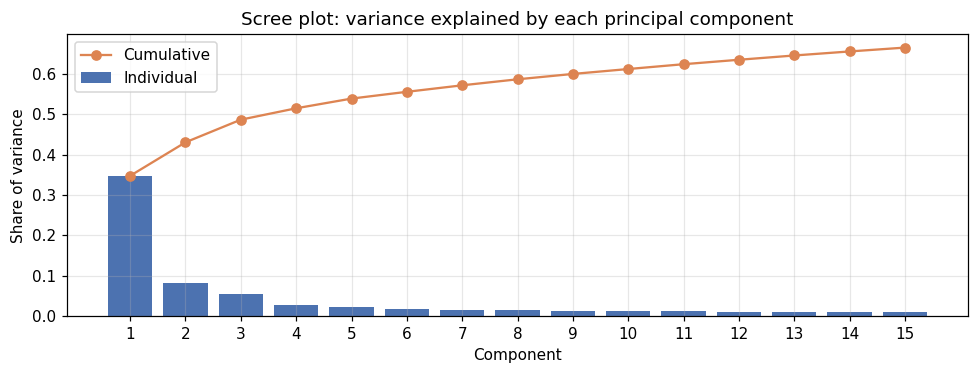

In [5]:
Z, U, s, Vt = pca_svd(excess_returns)           # standardize, SVD, and fix component signs
X = Z.T.values                                   # n_stocks x n_days
tickers_final = list(Z.columns)
sectors_final = np.array([sector_map[t] for t in tickers_final])
dates = Z.index

explained = s**2 / np.sum(s**2)
for i in range(3):
    print(f"PC{i+1}: {explained[i]:.2%} of variance")
print(f"First 3 components combined: {explained[:3].sum():.2%}")

n_show = 15
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(1, n_show + 1), explained[:n_show], color="#4c72b0", label="Individual")
ax.plot(range(1, n_show + 1), np.cumsum(explained[:n_show]), "o-", color="#dd8452", label="Cumulative")
ax.set_xlabel("Component"); ax.set_ylabel("Share of variance")
ax.set_title("Scree plot: variance explained by each principal component")
ax.set_xticks(range(1, n_show + 1)); ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "scree.png", dpi=150, bbox_inches="tight")
plt.show()

The first component explains about 35% of the variance by itself and the first three explain about 49% together. After the third component the scree plot flattens out a lot, so there is one big shared factor and then a few smaller ones.

## Principal Components Over Time

Now that we have the first 3 components we will plot them to see the variance in excess returns.

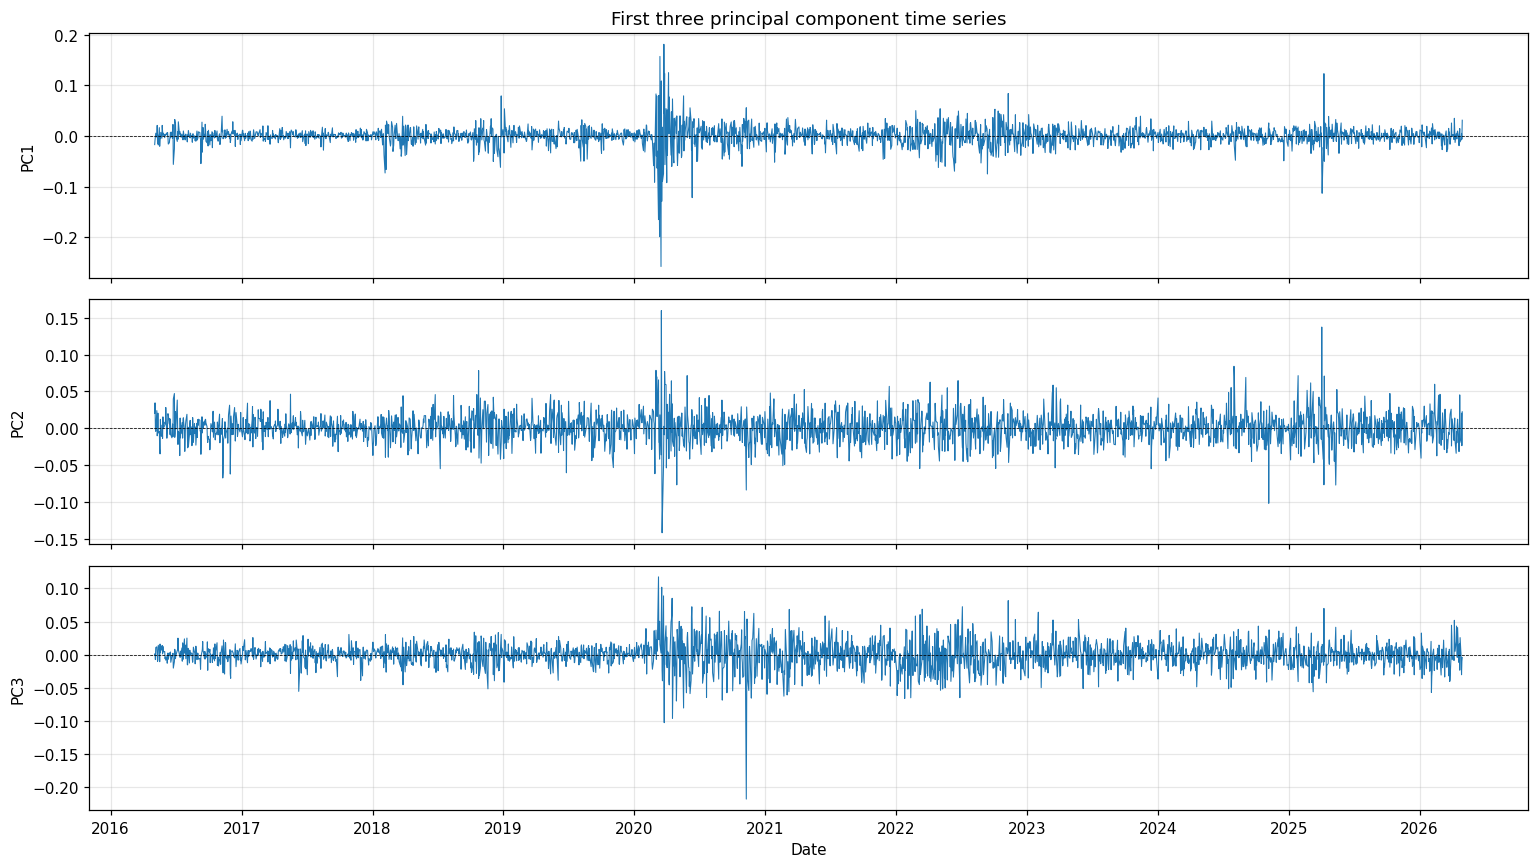

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(dates, Vt[i], linewidth=0.7)
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.set_ylabel(f"PC{i+1}")
axes[0].set_title("First three principal component time series")
axes[-1].set_xlabel("Date")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "pc_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

We can clearly see that all three of the components seem to have sharp spikes around 2020 (COVID) which matches with what we would believe to be the dominant market factor. PC2 and PC3 capture cross sectional variation rather than the total market variation. However both PC2 and PC3 seem to have a big volatility in 2020 as well. PC1 seems to have increased variance during the 2022 Fed rate hike and also a sharp spike in April 2025, most likely from the tariffs.

## Sector Loadings

To see what each component actually represents we can average the loadings of the stocks in each sector. A loading is roughly the correlation between a stock and that component.

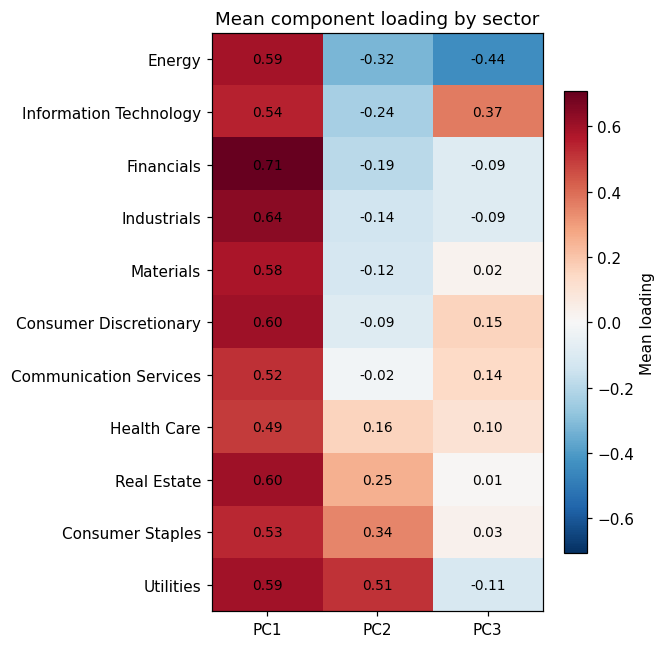

In [7]:
n_days = X.shape[1]
loadings = pd.DataFrame(U[:, :3] * s[:3] / np.sqrt(n_days - 1),
                        index=tickers_final, columns=["PC1", "PC2", "PC3"])
sector_loadings = loadings.groupby(sectors_final).mean().sort_values("PC2")

fig, ax = plt.subplots(figsize=(6, 6))
lim = np.abs(sector_loadings.values).max()
im = ax.imshow(sector_loadings.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(sector_loadings.columns)
ax.set_yticks(range(len(sector_loadings))); ax.set_yticklabels(sector_loadings.index)
ax.grid(False)
for (r, c), v in np.ndenumerate(sector_loadings.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8, label="Mean loading")
ax.set_title("Mean component loading by sector")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "sector_loadings.png", dpi=150, bbox_inches="tight")
plt.show()

PC1 is the market factor since every sector loads positively on it. PC2 separates the defensive sectors (utilities, consumer staples and real estate) from the more cyclical ones like energy, tech and financials. PC3 is mostly tech against energy. This also explains why utilities and energy end up on opposite ends of each other in the plots below.

## Dimensionality Reduction: SVD vs t-SNE vs UMAP

For t-SNE and UMAP, each stock is represented by its scores on the first 10 components instead of only the first 3, so they have more information to work with than the SVD plot. To measure how well each method groups the sectors we also compute the 5 nearest neighbor sector purity, which is the fraction of each stock's 5 closest stocks that are in the same sector. If the stocks were grouped randomly this would be about 0.08.

5-NN sector purity:
PCA (10 components)    0.673
PCA (PC2 vs PC3)       0.373
t-SNE                  0.684
UMAP                   0.688
Random (chance)        0.082


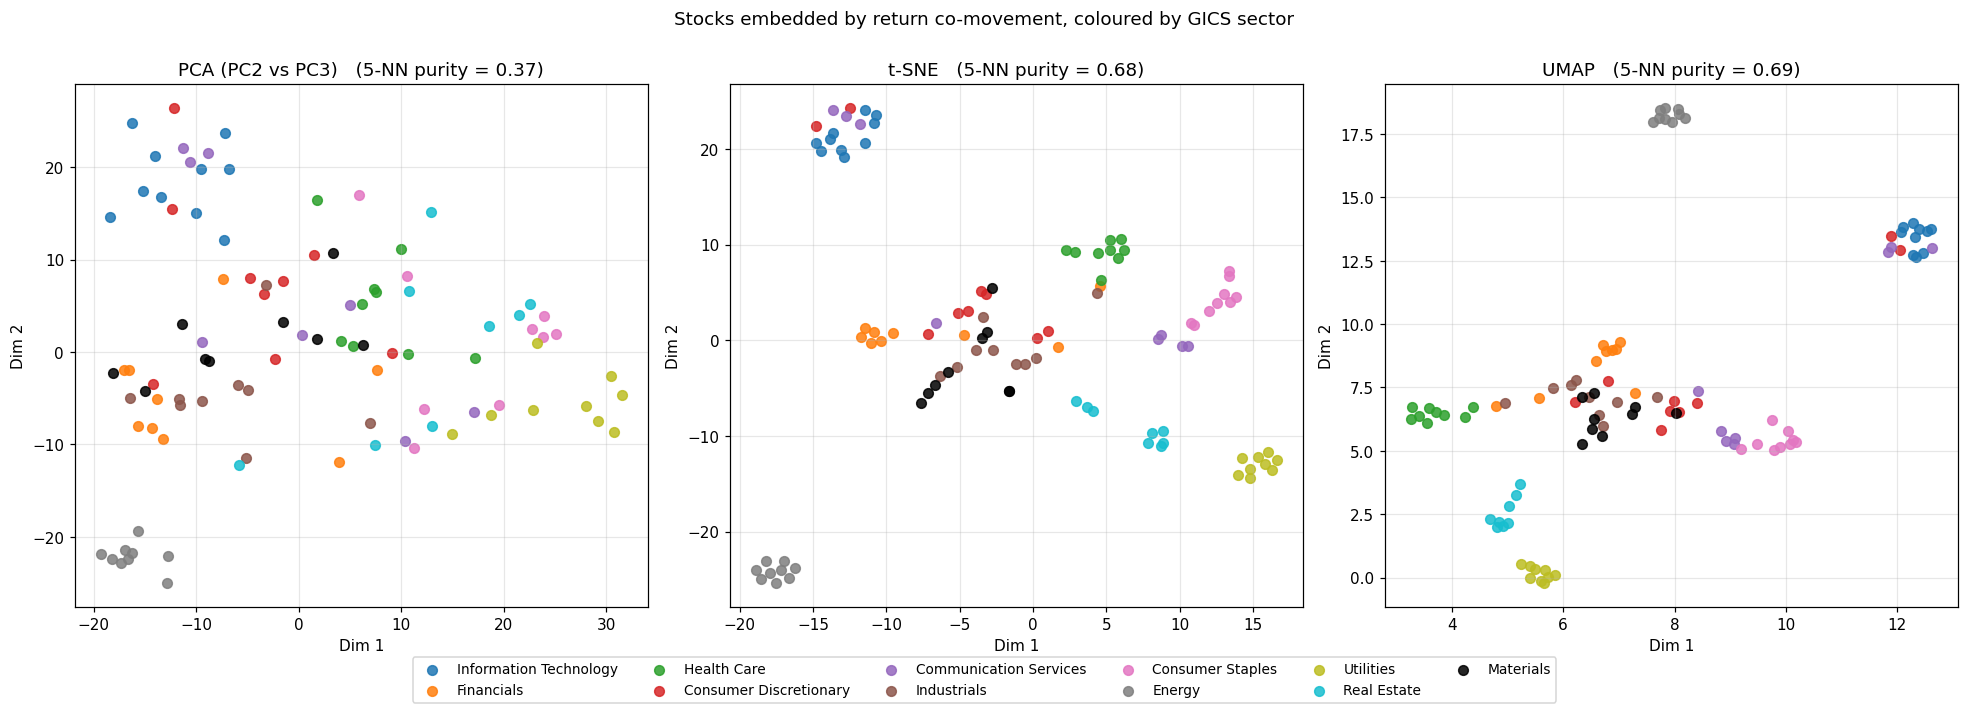

In [8]:
N_PCS_EMBED = 10
pc_scores = U[:, :N_PCS_EMBED] * s[:N_PCS_EMBED]

tsne_2d = TSNE(n_components=2, perplexity=10, init="pca", random_state=SEED).fit_transform(pc_scores)
umap_2d = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.2, random_state=SEED).fit_transform(pc_scores)


chance_purity = chance_sector_purity(sectors_final)

representations = {
    "PCA (10 components)": pc_scores,
    "PCA (PC2 vs PC3)": pc_scores[:, 1:3],
    "t-SNE": tsne_2d,
    "UMAP": umap_2d,
}
purity = pd.Series({name: knn_sector_purity(c, sectors_final) for name, c in representations.items()})
purity["Random (chance)"] = chance_purity
print("5-NN sector purity:")
print(purity.round(3).to_string())

# 11 sectors need 11 distinct colours (the default cycle only has 10)
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b",
           "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#000000"]
sector_colors = dict(zip(TICKERS_BY_SECTOR, palette))

plots = {"PCA (PC2 vs PC3)": pc_scores[:, 1:3], "t-SNE": tsne_2d, "UMAP": umap_2d}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (title, coords) in zip(axes, plots.items()):
    for sector, color in sector_colors.items():
        m = sectors_final == sector
        ax.scatter(coords[m, 0], coords[m, 1], color=color, label=sector, s=40, alpha=0.85)
    ax.set_title(f"{title}   (5-NN purity = {purity[title]:.2f})")
    ax.set_xlabel("Dim 1"); ax.set_ylabel("Dim 2")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.suptitle("Stocks embedded by return co-movement, coloured by GICS sector", y=1.0)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "embeddings.png", dpi=150, bbox_inches="tight")
plt.show()

The SVD projection shows there is some sector separation, utilities and energy seem to be very separated (opposite ends to each other) which is consistent with observations of the sectors. Many of the other sectors overlap a lot, which might show that the GICS doesn't fully determine the return movement and variation.

For T-SNE a perplexity of 10 was chosen since the sample size was relatively small and because in the original data around 9-10 stocks were in the same sector. For U-Map, a k of 10 and min_dist of 0.2 was chosen for a similar reason, keeping the neighborhood local. U-Map places energy far away from every other sector but still seems to separate the rest of the sectors as well. Both nonlinear embeddings show a lot more cohesion within each sector than the SVD mapping, with a purity of 0.68 for t-SNE and 0.69 for U-Map compared to 0.37 for the SVD plot, but there is still some mixing. Tech and communication services end up together since stocks like GOOGL, META and NFLX move like tech stocks, and consumer discretionary is split between AMZN and TSLA and the more traditional retailers. This shows that the overall market behavior dominates most of the movement, but once that is taken out, the sectors are the main structure that is left. (The t-SNE and U-Map purity can change by about 0.02 on different computers.)

## Limitations

Since the stocks were picked as large companies today, the analysis has survivorship bias as mentioned above. Yahoo Finance also changes adjusted prices over time and removes delisted tickers, which is why the data is saved in `data/`; downloading it again later could change the results slightly. The PCA is also done over the whole ten years at once, so a rolling window would be a good next step to see how the structure changes over time.